# Saldo de las cuentas de la Seguridad Social

In [ ]:
# Parámetros de la gráfica
SLUG = "seguridad-social"  # carpeta en research/temas/
GRAFICA_ID = "saldo-seguridad-social"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Saldo de las cuentas de la Seguridad Social"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% del PIB (negativo: déficit; positivo: superávit)"  # capacidad (+) o necesidad (−) de financiación
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = 0  # línea horizontal en el 0: separa el déficit (debajo) del superávit (encima)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** La diferencia entre lo que ingresan y lo que gastan en un año los *fondos de la Seguridad Social*, uno de los cuatro subsectores de las administraciones públicas en la contabilidad nacional (junto al Estado, las comunidades autónomas y las entidades locales), en porcentaje del PIB. En contabilidad nacional se llama *capacidad (+) o necesidad (−) de financiación* (partida B.9) del subsector S.1314.

**Cómo se lee.** Un valor de −1 significa que ese año los fondos de la Seguridad Social gastaron más de lo que ingresaron por un importe equivalente al 1 % del PIB. Un valor positivo es un superávit. La línea en el 0 separa los dos casos.

**Limitaciones.**
- **Incluye las transferencias del Estado.** Los ingresos no son solo cotizaciones: también cuentan las transferencias que la Seguridad Social recibe del Estado, que en España pagan, entre otras cosas, las pensiones no contributivas, los complementos a mínimos y, desde 2022, los gastos que la Ley 21/2021 asigna al Estado. Por eso el saldo no dice si las cotizaciones bastan para pagar las pensiones: si el Estado transfiere más, el saldo mejora aunque no cambien ni las cotizaciones ni las pensiones. La sección 3 calcula cuánto pesan esas transferencias.
- **No es solo el sistema de pensiones.** En España el subsector incluye también el Servicio Público de Empleo Estatal (prestaciones por desempleo) y el Fondo de Garantía Salarial, y no incluye las pensiones de los funcionarios de clases pasivas, que paga el Estado.
- **Cada país organiza el subsector a su manera.** En Estados Unidos no existe: la contabilidad nacional registra la Social Security federal dentro de la administración central, así que la serie queda vacía. En Canadá recoge sobre todo los planes de pensiones públicos de Canadá y de Quebec, que acumulan un fondo de reserva y por eso suelen tener superávit. La OCDE no publica una media de este subsector.
- Eurostat da el subsector español desde 1995, primer año de la contabilidad nacional vigente (SEC 2010).

## 2. Descarga

- **España y UE-27:** Eurostat, cuentas no financieras anuales de las administraciones públicas (`gov_10a_main`), subsector `S1314` (fondos de la Seguridad Social), partida `B9` (capacidad o necesidad de financiación), en % del PIB (`PC_GDP`).
- **Canadá:** OCDE, cuentas de las administraciones públicas (tabla 12, `OECD.SDD.NAD,DSD_NASEC10@DF_TABLE12`), subsector `S1314`, partida `B9`, en moneda nacional, dividida entre el PIB a precios corrientes en moneda nacional (OCDE, tabla 1, `DSD_NAMAIN10@DF_TABLE1_EXPENDITURE`, `B1GQ`). La tabla 12 solo publica importes, no porcentajes del PIB.
- **Estados Unidos:** la misma tabla 12 de la OCDE, para comprobar que no publica el subsector `S1314`.

Solo para las comprobaciones y las notas de la sección 3 (no se publican como series): el mismo saldo de España en la OCDE, y los ingresos por cotizaciones sociales (`D61REC`), las otras transferencias corrientes recibidas (`D7REC`) y las prestaciones sociales pagadas (`D62PAY`) del subsector español en Eurostat.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import eurostat, oecd
from lib.tipos import FuenteMeta

# Eurostat: saldo del subsector fondos de la Seguridad Social, % del PIB
FILTROS = {"freq": "A", "unit": "PC_GDP", "sector": "S1314", "na_item": "B9"}
eu, fuentes_eu = eurostat.get("gov_10a_main", FILTROS, desde=DESDE)

# Partidas del subsector español en Eurostat, solo para las notas
partidas = {}
for item in ("D61REC", "D7REC", "D62PAY", "TR", "TE"):
    d, _ = eurostat.get("gov_10a_main", {**FILTROS, "na_item": item}, geos={"ES": "espana"}, desde=DESDE)
    partidas[item] = d.set_index("periodo")["valor"]

# OCDE, tabla 12: saldo (B9) del subsector S1314 en moneda nacional.
# Dimensiones: FREQ.REF_AREA.SECTOR.COUNTERPART_SECTOR.ACCOUNTING_ENTRY.TRANSACTION.INSTR_ASSET.EXPENDITURE.
#              UNIT_MEASURE.VALUATION.PRICE_BASE.TRANSFORMATION.TABLE_IDENTIFIER
DATAFLOW_T12 = "OECD.SDD.NAD,DSD_NASEC10@DF_TABLE12,1.1"
CLAVE_T12 = "A.{AREA}.S1314._Z.B.B9._Z._Z.XDC.S.V.N.T0200"
DATAFLOW_PIB = "OECD.SDD.NAD,DSD_NAMAIN10@DF_TABLE1_EXPENDITURE,2.0"
# FREQ.REF_AREA.SECTOR.COUNTERPART_SECTOR.TRANSACTION.INSTR_ASSET.ACTIVITY.EXPENDITURE.UNIT_MEASURE.PRICE_BASE.
# TRANSFORMATION.TABLE_IDENTIFIER
CLAVE_PIB = "A.{AREA}.S1.S1.B1GQ._Z._Z._Z.XDC.V.N.T0102"
AREAS_T12 = {"CAN": "canada", "ESP": "espana_ocde", "USA": "eeuu"}
t12, _ = oecd.get(DATAFLOW_T12, CLAVE_T12, areas=AREAS_T12, desde=DESDE)
pib, _ = oecd.get(DATAFLOW_PIB, CLAVE_PIB, areas=AREAS_T12, desde=DESDE)
print("Áreas con el subsector S1314 en la tabla 12 de la OCDE:", sorted(t12["serie"].unique()))

Áreas con el subsector S1314 en la tabla 12 de la OCDE: ['canada', 'espana_ocde']


## 3. Transformación

- **España y UE-27:** sin transformar.
- **Canadá:** saldo del subsector en moneda nacional entre el PIB en moneda nacional, por 100.
- **Estados Unidos y OCDE:** `null` (el subsector no existe en las cuentas de Estados Unidos y la OCDE no publica su media).

In [ ]:
serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"]

can = (serie(t12, "canada") / serie(pib, "canada") * 100).dropna()
espana_ocde = (serie(t12, "espana_ocde") / serie(pib, "espana_ocde") * 100).dropna()
assert "eeuu" not in set(t12["serie"]), "la OCDE publica ahora el subsector S1314 de EE. UU.: revisar la nota"

df = pd.concat(
    [eu, pd.DataFrame({"serie": "canada", "periodo": can.index, "valor": can.values})], ignore_index=True
)
assert df["valor"].between(-15, 15).all(), "saldo fuera de rango: ¿unidades?"


def anadir_sin_dato(df, fuentes, sin_dato):
    """Añade las series de la cesta sin dato comparable (todo `null`) con la fuente consultada."""
    vacias = pd.DataFrame({"serie": list(sin_dato), "periodo": DESDE, "valor": float("nan")})
    extra = [FuenteMeta(s, org, cod, url, HOY) for s, (org, cod, url) in sin_dato.items()]
    return pd.concat([df, vacias], ignore_index=True), [*fuentes, *extra]


HOY = fuentes_eu[0].fecha_consulta
fuentes = [
    FuenteMeta(f.serie, f.organismo, "gov_10a_main (sector=S1314, na_item=B9, unit=PC_GDP)", f.url, f.fecha_consulta)
    for f in fuentes_eu
]
fuentes.append(
    FuenteMeta(
        "canada", oecd.ORGANISMO,
        "DSD_NASEC10@DF_TABLE12 (S1314, B9, XDC) entre DSD_NAMAIN10@DF_TABLE1_EXPENDITURE (B1GQ, XDC)",
        oecd.URL_EXPLORER, HOY,
    )
)
T12 = (oecd.ORGANISMO, "DSD_NASEC10@DF_TABLE12 (S1314, B9): sin el subsector fondos de la Seguridad Social", oecd.URL_EXPLORER)
df, fuentes = anadir_sin_dato(df, fuentes, {
    "ocde": (oecd.ORGANISMO, "DSD_NASEC10@DF_TABLE12 (S1314, B9): sin media de la OCDE", oecd.URL_EXPLORER),
    "eeuu": T12,
})
df.pivot(index="periodo", columns="serie", values="valor").round(2).tail(12)

serie,canada,eeuu,espana,ocde,ue27
periodo,,,,,
2014,0.57,NaN,-1.0,NaN,-0.2
2015,0.60,NaN,-1.2,NaN,-0.1
2016,0.54,NaN,-1.5,NaN,0.0
2017,0.57,NaN,-1.4,NaN,0.2
2018,0.58,NaN,-1.4,NaN,0.3
2019,0.67,NaN,-1.3,NaN,0.2
2020,0.45,NaN,-2.4,NaN,-0.7
2021,0.82,NaN,-0.9,NaN,0.0
2022,0.90,NaN,-0.4,NaN,0.3


### Comprobaciones

1. España: el saldo de Eurostat frente al calculado con la tabla 12 de la OCDE (deben coincidir: las dos salen de la notificación de España).
2. Peso de las transferencias: cotizaciones sociales, otras transferencias corrientes recibidas (sobre todo del Estado) y prestaciones sociales pagadas por el subsector español, en % del PIB, y el saldo que quedaría sin esas transferencias (solo como orden de magnitud: no todo `D7REC` viene del Estado).

In [ ]:
def fmt(x, decimales=1):
    return estilos.formato_es(x, decimales).replace("-", "−")


comp = pd.DataFrame({"Eurostat": serie(eu, "espana"), "OCDE (calculado)": espana_ocde}).dropna()
comp["dif."] = comp["Eurostat"] - comp["OCDE (calculado)"]
DIF_MAX = comp["dif."].abs().max()
print(f"España: diferencia máxima Eurostat − OCDE {DIF_MAX:.3f} puntos ({comp.index.min()}-{comp.index.max()})")

p = pd.DataFrame(partidas)
p["B9"] = serie(eu, "espana")
p["B9 sin D7REC"] = p["B9"] - p["D7REC"]
display(p.round(2).tail(15))
ULT = int(p.dropna().index.max())
D7_ULT, B9_ULT, SIN_ULT = p.loc[ULT, "D7REC"], p.loc[ULT, "B9"], p.loc[ULT, "B9 sin D7REC"]
D7_MIN_ANIO = int(p["D7REC"].idxmin())
D7_MIN = p["D7REC"].min()

España: diferencia máxima Eurostat − OCDE 0.050 puntos (1995-2025)


,D61REC,D7REC,D62PAY,TR,TE,B9,B9 sin D7REC
periodo,,,,,,,
2011,11.6,2.8,13.5,14.7,14.8,-0.1,-2.9
2012,11.4,2.7,14.4,14.5,15.5,-1.0,-3.7
2013,11.3,3.0,14.8,14.6,15.7,-1.1,-4.1
2014,11.4,2.8,14.5,14.4,15.4,-1.0,-3.8
2015,11.1,2.2,13.8,13.5,14.7,-1.2,-3.4
2016,11.1,1.6,13.5,12.9,14.4,-1.5,-3.1
2017,11.3,1.3,13.2,12.7,14.1,-1.4,-2.7
2018,11.5,1.3,13.4,12.8,14.2,-1.4,-2.7
2019,12.0,1.3,13.7,13.3,14.6,-1.3,-2.6


### Notas

Una frase por decisión. Las cifras de las notas salen de las comprobaciones anteriores.

In [ ]:
NOTAS = [
    "España y UE-27: Eurostat, cuentas no financieras de las administraciones públicas (gov_10a_main), subsector "
    "fondos de la Seguridad Social (S1314), capacidad (+) o necesidad (−) de financiación (B9), en % del PIB; "
    "contabilidad nacional SEC 2010 desde 1995. Media UE-27: agregado de composición actual (EU27_2020).",
    f"El saldo incluye las transferencias que la Seguridad Social recibe del Estado, por lo que no mide si las "
    f"cotizaciones bastan para pagar las prestaciones: en {ULT}, las otras transferencias corrientes que recibió el "
    f"subsector español (partida D7REC, sobre todo del Estado) equivalían al {fmt(D7_ULT)} % del PIB, frente a un "
    f"saldo del {fmt(B9_ULT)} % (Eurostat, gov_10a_main). Esas transferencias pagan, entre otras cosas, las "
    f"pensiones no contributivas, los complementos a mínimos y, desde 2022, los gastos que la Ley 21/2021 asigna al "
    f"Estado.",
    "En España, el subsector incluye también el Servicio Público de Empleo Estatal (prestaciones por desempleo) y el "
    "Fondo de Garantía Salarial, y no incluye las pensiones de clases pasivas de los funcionarios, que paga el Estado.",
    "Canadá: OCDE, cuentas de las administraciones públicas (tabla 12, DSD_NASEC10@DF_TABLE12), saldo (B9) del "
    "subsector S1314 en moneda nacional, dividido entre el PIB a precios corrientes (tabla 1, B1GQ). Recoge sobre "
    "todo los planes de pensiones públicos de Canadá y de Quebec, que acumulan un fondo de reserva.",
    "EE. UU.: sin dato. Su contabilidad nacional no tiene el subsector fondos de la Seguridad Social: la Social "
    "Security federal se registra dentro de la administración central, y la OCDE no publica el subsector S1314.",
    "OCDE: sin dato. La OCDE no publica la media de este subsector.",
    f"España: el saldo de Eurostat coincide con el calculado con la tabla 12 de la OCDE (diferencia máxima de "
    f"{fmt(DIF_MAX, 2)} puntos, {comp.index.min()}-{comp.index.max()}).",
]
for n in NOTAS:
    print("-", n)

- España y UE-27: Eurostat, cuentas no financieras de las administraciones públicas (gov_10a_main), subsector fondos de la Seguridad Social (S1314), capacidad (+) o necesidad (−) de financiación (B9), en % del PIB; contabilidad nacional SEC 2010 desde 1995. Media UE-27: agregado de composición actual (EU27_2020).
- El saldo incluye las transferencias que la Seguridad Social recibe del Estado, por lo que no mide si las cotizaciones bastan para pagar las prestaciones: en 2025, las otras transferencias corrientes que recibió el subsector español (partida D7REC, sobre todo del Estado) equivalían al 2,9 % del PIB, frente a un saldo del −0,3 % (Eurostat, gov_10a_main). Esas transferencias pagan, entre otras cosas, las pensiones no contributivas, los complementos a mínimos y, desde 2022, los gastos que la Ley 21/2021 asigna al Estado.
- En España, el subsector incluye también el Servicio Público de Empleo Estatal (prestaciones por desempleo) y el Fondo de Garantía Salarial, y no incluye las p

## 4. Visualización

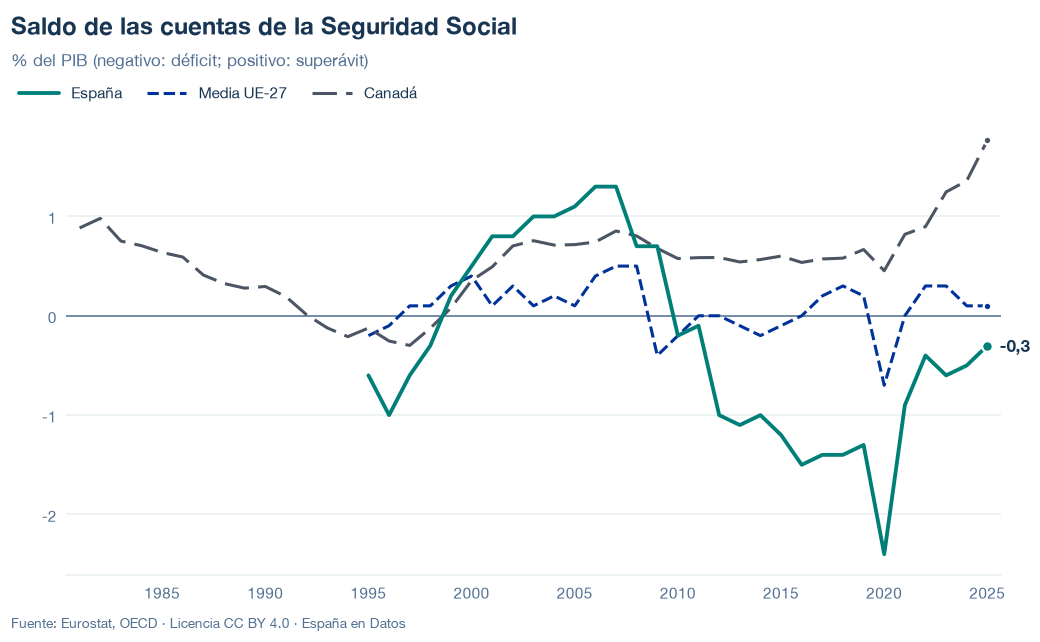

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/saldo-seguridad-social.json y data/saldo-seguridad-social.csv


## 6. Fuentes, notas y licencia

- Eurostat, `gov_10a_main` (`S1314`, `B9`, `PC_GDP`) para España y la UE-27; `D61REC`, `D7REC`, `D62PAY`, `TR` y `TE` del subsector español para las notas.
- OCDE, tabla 12 de las cuentas de las administraciones públicas (`OECD.SDD.NAD,DSD_NASEC10@DF_TABLE12,1.1`) y tabla 1 de las cuentas nacionales (`OECD.SDD.NAD,DSD_NAMAIN10@DF_TABLE1_EXPENDITURE,2.0`) para Canadá y la comprobación de España.

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.